# Linear regression practice

Mr. Harry: *"Read up on linear regression and logistic regression, and practise both thoroughly."*

**Linear regression** predicts a **number** (e.g. weight in kg). **Logistic regression** predicts a **probability of a class** (e.g. heart disease yes/no) — see notebooks 03 and 04.

Data: the 5,000 synthetic patient records from the earlier AI & ES assignment (Height → Weight).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_excel('../data/synthetic_patient_records.xlsx', sheet_name='Patient_Records')
adults = df[df['Age'] >= 18]
X = adults[['Height_cm']]; y = adults['Weight_kg']
print(len(adults), 'adult records')

4383 adult records


## 1. The formula by hand: y = b0 + b1·x
b1 (slope) = covariance(x, y) / variance(x); b0 (intercept) = mean(y) − b1·mean(x).

In [2]:
x = X['Height_cm'].values; yy = y.values
b1 = np.cov(x, yy, ddof=1)[0, 1] / np.var(x, ddof=1)
b0 = yy.mean() - b1 * x.mean()
print(f'By hand:      weight = {b0:.2f} + {b1:.3f} × height')
lr = LinearRegression().fit(X, y)
print(f'scikit-learn: weight = {lr.intercept_:.2f} + {lr.coef_[0]:.3f} × height   (should match)')

By hand:      weight = -54.37 + 0.725 × height
scikit-learn: weight = -54.37 + 0.725 × height   (should match)


**Reading the slope:** every extra 1 cm of height adds about b1 kg of predicted weight.

MAE  = 9.08 kg  (average size of the error)
RMSE = 11.48 kg  (punishes big errors more)
R²   = 0.253     (share of the variation in weight explained by height)


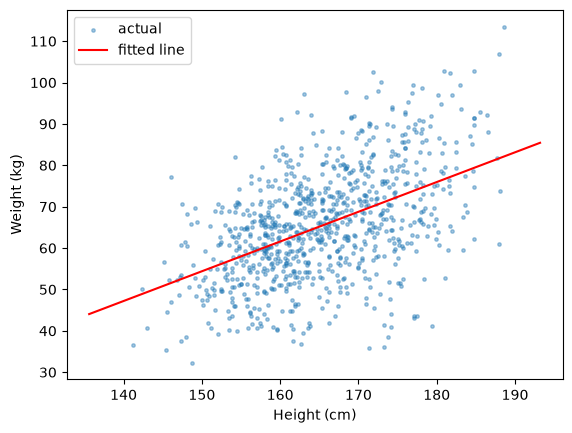

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
lr = LinearRegression().fit(X_train, y_train); pred = lr.predict(X_test)
print('MAE  = %.2f kg  (average size of the error)' % mean_absolute_error(y_test, pred))
print('RMSE = %.2f kg  (punishes big errors more)' % mean_squared_error(y_test, pred) ** 0.5)
print('R²   = %.3f     (share of the variation in weight explained by height)' % r2_score(y_test, pred))
plt.scatter(X_test, y_test, s=6, alpha=.4, label='actual')
xs = np.linspace(X['Height_cm'].min(), X['Height_cm'].max(), 50).reshape(-1, 1)
plt.plot(xs, lr.predict(pd.DataFrame(xs, columns=['Height_cm'])), 'r', label='fitted line')
plt.xlabel('Height (cm)'); plt.ylabel('Weight (kg)'); plt.legend(); plt.show()

## 2. Residuals — checking the model
A residual = actual − predicted. Good linear models have residuals scattered randomly around 0 with no pattern.

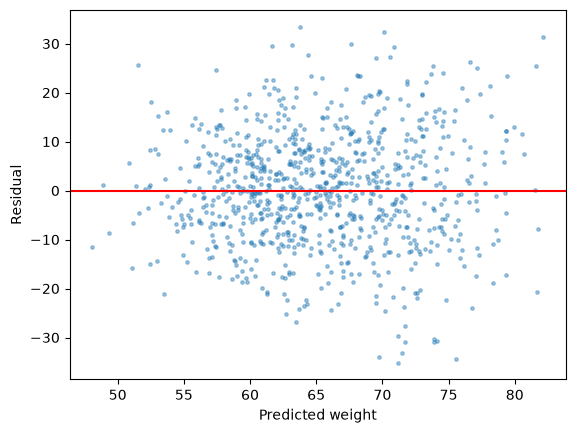

In [4]:
res = y_test - pred
plt.scatter(pred, res, s=6, alpha=.4); plt.axhline(0, color='r'); plt.xlabel('Predicted weight'); plt.ylabel('Residual'); plt.show()

## 3. Multiple linear regression (more than one input)

In [5]:
X2 = adults[['Height_cm', 'Age', 'Haemoglobin_g_dL']]
X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, random_state=42)
m2 = LinearRegression().fit(X_train, y_train)
print(dict(zip(X2.columns, m2.coef_.round(3))), 'intercept', round(m2.intercept_, 2))
print('R² with 3 inputs = %.3f' % r2_score(y_test, m2.predict(X_test)))

{'Height_cm': np.float64(0.713), 'Age': np.float64(0.164), 'Haemoglobin_g_dL': np.float64(0.119)} intercept -60.68
R² with 3 inputs = 0.299


## 4. Conclusion
- The hand-calculated line and scikit-learn agree exactly: **weight ≈ −54.4 + 0.725 × height** — each extra cm of height adds about 0.73 kg.
- **R² = 0.25**: height explains only a quarter of the variation in adult weight; the typical error is about **9 kg (MAE)**. That makes sense, because in this dataset weight was generated from BMI *and* height, so people of the same height can have very different weights.
- Adding age and haemoglobin raises R² only to **0.30** — most of the remaining variation comes from BMI, which we deliberately left out (BMI is calculated *from* weight, so using it would be cheating / data leakage).